# Testing different similarity metrics on OpenAlex papers

## Literature Review
Recent research uses distance and similarity metrics in various ways. These methods are not restricted to text embeddings and the methods can be applied to any data type that can be represented numerically. For example, in cognitive neuroscience, Ng et al. (2024) used Manhattan distance and k-median to cluster brain activation vectors from each time point into 6 common patterns of brain activation. Another paper by Alasehir & Acarturk (2022) used Doc2Vec on publication titles and abstracts to examine the scientific fields present in cognitive science. They did this using document embeddings on papers from adjecent fields (psychology, linguistics, anthropology, etc.) and then projected cognitive science papers onto it and used cosine similarity to assess which adjecent fields are most strongly represented in cognitive science. Motohashi, Koshiba, and Ikeuchi (2024) also used text from publications and patents, turning them into 300-dimensional document vectors. They then use cosine similarity to find the 200 nearest neighbors for each document and use the composition of those neighbors as a measure of scientific/technological intensity (e.g. if 180 of a patent's neighbors are papers then the patent has a science intensity of 180/200 = 0.9). They validated the use of cosine similarity by comparing random document pairs with pairs that cite one another and found that cosine similarity is higher for the latter pair. They observed this over time and found that scientific intensity increases for patents while technological intensity decreases for papers. They explained this as meaning that inventions/technology relies on science while technological developments may not feed back into science research. The scenario they used pertained to the pharmaceutical industry and life sciences. 

Although written text is very different than neural data, the representation of the data as numerical vectors allows the implementation of these similarity metrics. It is also important to note that the choice of similarity metric and its respective clustering method is not arbitrary. For example, Ng et al. claimed to use Manhattan distance due to Euclidean distance's poorer performance with high-dimensional data (360 dimensions - one per specific brain region that contains the averaged activations of voxels within it). However, as a result of using Manhattan distance, they clustered using k-medians rather than k-means since k-means optimizes for the smallest squared Euclidean distance within a cluster using the mean as the centroid. In contrast, when Manhattan distances are used, the median coordinates optimize for the smallest Manhattan distance, and using the mean would generally result in larger Manhattan distances within the cluster.

The two papers that use text embeddings are relevant to my project. I am planning on using dense embeddings from a pre-trained model to represent publications as the document embedding of their abstracts. I am intruiged by the use of a model trained on embeddings with ground truth labels from Alasehir & Acarturk (2022). They used papers from journals that specializes in a specific discipline (e.g. Journal of Personality and Social Psychology), which although does not guarantee that every paper is a psychology paper, gets arguably much close than OpenAlex. The limitation with OpenAlex's topic labels is that they were generated by a text classifier that is only 81.7% accurate. I could consider cross-referencing paper titles from a field-specific journals and only using those in my OpenAlex dataset to improve the validity of topic labels. Motohashi, Koshiba, and Ikeuchi provide a method to answer a relevant question: Are themes becoming more interdisciplinary? I would implement this using the composition of topic labels from k-nearest neighbors to measure interdisciplinarity of a given paper. Although recent NLP papers appear to favor cosine similarity, I will also be testing other distance metrics for my embeddings.

In [1]:
import numpy as np
import pandas as pd
import sklearn
import sentence_transformers
import json

### Import data

In [2]:
works = pd.read_csv("api_test/data_2013_2016/works.csv")
print(f"Number of works: {len(works)}")
works.head()

Number of works: 800


,openalex_id,doi,title,abstract,publication_year,publication_date,type,language,cited_by_count,referenced_works_count,referenced_works,is_oa,oa_status,oa_url,source_name,primary_topic,primary_topic_id,authors,author_ids
0,https://openalex.org/W2130781952,https://doi.org/10.1002/adhm.201300113,A New Design and Application of Bioelastomers ...,Glaucoma drainage device (GDD) implantation is...,2013,2013-07-09,article,en,4,22,https://openalex.org/W194547286; https://opena...,False,closed,NaN,Advanced Healthcare Materials,Glaucoma and retinal disorders,https://openalex.org/T10250,Quang Minh Luong; Lei Shang; Marcus Ang; Jen F...,https://openalex.org/A5060459854; ; https://op...
1,https://openalex.org/W2768710832,NaN,Being An Effective Communicator In A Team,When it came to pick a subject for our researc...,2013,2013-01-01,article,en,0,0,NaN,False,closed,NaN,PDXScholar (Portland State University),Organizational Learning and Leadership,https://openalex.org/T13163,Ashish Mishra; Jared Omulindi; Philip D. Jaffé...,https://openalex.org/A5100660163; https://open...
2,https://openalex.org/W2726385890,NaN,Dynamic Time Slot Assignment Scheme for Pictur...,NaN,2013,2013-02-28,article,en,0,0,NaN,False,closed,NaN,IEICE Technical Report; IEICE Tech. Rep.,Energy Efficient Wireless Sensor Networks,https://openalex.org/T10080,Nagai Ryosuke; Sakata Shiro; Komuro Nobuyoshi,https://openalex.org/A5087433314; https://open...
3,https://openalex.org/W186702817,https://doi.org/10.17077/0003-4827.1745,This Wicked Rebellion: Wisconsin Civil War Sol...,in the modern era.Historians mostly ignored th...,2013,2013-10-01,article,en,2,0,NaN,True,bronze,https://pubs.lib.uiowa.edu/annals-of-iowa/arti...,The Annals of Iowa,American History and Culture,https://openalex.org/T13025,Patrick G. Bass,https://openalex.org/A5088691622
4,https://openalex.org/W2004782196,https://doi.org/10.1016/j.aop.2013.05.017,WKB analysis of relativistic Stern–Gerlach mea...,NaN,2013,2013-06-13,article,en,18,35,https://openalex.org/W225340292; https://opena...,True,green,https://arxiv.org/pdf/1208.6434,Annals of Physics,Quantum Mechanics and Non-Hermitian Physics,https://openalex.org/T11262,Matthew C. Palmer; Maki Takahashi; Hans F. Wes...,; ;


### Add field/sub-field variables

In [3]:
taxonomy_columns = [
    "primary_topic_score",
    "primary_subfield", "primary_subfield_id",
    "primary_field", "primary_field_id",
    "primary_domain", "primary_domain_id",
]
missing_taxonomy_columns = [column for column in taxonomy_columns if column not in works.columns]

if missing_taxonomy_columns:
    with open("api_test/data_2013_2016/works_raw.json", encoding="utf-8") as file:
        raw_works = json.load(file)["results"]

    taxonomy_rows = []
    for work in raw_works:
        topic = work.get("primary_topic") or {}
        subfield = topic.get("subfield") or {}
        field = topic.get("field") or {}
        domain = topic.get("domain") or {}
        taxonomy_rows.append({
            "openalex_id": work["id"],
            "primary_topic_score": topic.get("score"),
            "primary_subfield": subfield.get("display_name"),
            "primary_subfield_id": subfield.get("id"),
            "primary_field": field.get("display_name"),
            "primary_field_id": field.get("id"),
            "primary_domain": domain.get("display_name"),
            "primary_domain_id": domain.get("id"),
        })

    taxonomy = pd.DataFrame(taxonomy_rows).set_index("openalex_id")
    if not taxonomy.index.is_unique:
        raise ValueError("Duplicate OpenAlex IDs in works_raw.json")
    if set(works["openalex_id"]) != set(taxonomy.index):
        raise ValueError("works.csv and works_raw.json contain different OpenAlex IDs")

    original_ids = works["openalex_id"].reset_index(drop=True)
    works = works.join(taxonomy[missing_taxonomy_columns], on="openalex_id", validate="one_to_one")
    if not works["openalex_id"].reset_index(drop=True).equals(original_ids):
        raise ValueError("Taxonomy join changed work order")

print(f"Primary taxonomy available for {works['primary_field_id'].notna().sum()} of {len(works)} works")

Primary taxonomy available for 797 of 800 works


In [4]:
# remove rows with missing abstracts
works = works.dropna(subset=["abstract"])

# remove rows with tiny abstracts
works = works[works["abstract"].str.len() > 20]
print(f"Number of works after cleaning: {len(works)}")

Number of works after cleaning: 502


In [5]:
sorted(works["abstract"], reverse=False)

['"A collection of essays that explore the transatlantic German cultures and identities of the colonial period"...Provided by publisher',
 '"Foreword: probiotics and prebiotics – a field that is alive and kicking." Beneficial Microbes, 7(1), pp. 1–2',
 '// Xin Sun 1, * , Shiwen Jiang 2, * , Jian Liu 1 , Huangzhen Wang 1 , Yiwen Zhang 1 , Shou-Ching Tang 3, 4 , Jichang Wang 5 , Ning Du 1 , Chongwen Xu 1 , Chenguang Wang 6 , Sida Qin 1 , Jia Zhang 1 , Dapeng Liu 1 , Yunfeng Zhang 1 , Xiaojun Li 1 , Jiansheng Wang 1 , Jun Dong 7 , Xin Wang 8 , Shaohua Xu 9 , Zhen Tao 10 , Fei Xu 11 , Jie Zhou 12 , Tao Wang 13 , Hong Ren 1 1 Department of Thoracic Surgery and Oncology, the First Affiliated Hospital of Xi’an Jiaotong University, Xi’an, Shaanxi Province, 710061, China 2 Department of Obstetrics and Gynecology, the Second Affiliated Hospital of Wenzhou Medical University, Wenzhou, Zhejiang Province, 325027, China 3 Breast Cancer Program and Interdisciplinary Translational Research Team, Georg

Some of are not valid abstracts, also should probably remove non-english abstracts?

### Generate document embeddings to test similarity metrics on

In [6]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

embeddings = embedding_model.encode(works["abstract"].tolist(), show_progress_bar=True)

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

### Check shape of output

In [15]:
print(embeddings.shape) # rows(abstracts) x columns(embeddings)

# example of one embedding (384 latent features/dimensions)
print(embeddings[0][:10]) # first 10 dimensions of the first abstract's embedding

(502, 384)
[-0.02168146 -0.06114104  0.11256856 -0.07322948 -0.05123238 -0.02665479
  0.09974257  0.10423435 -0.01161763  0.01009952]


### Testing similarity metrics
- cosine
- Euclidean
- Manhattan

In [16]:
from sklearn.metrics.pairwise import cosine_similarity

cos_sim_mat = cosine_similarity(embeddings)
cos_sim_mat.shape

(502, 502)

In [17]:
print(f"Cosine similarity between abstract 0 and 1: {cos_sim_mat[0][1]}")

Cosine similarity between abstract 0 and 1: -0.08616819977760315


In [18]:
# find the top 5 most similar abstracts to the first abstract
def top_neighbors(sim_matrix, i, k=5):
    return np.argsort(sim_matrix[i])[::-1][1:k+1]


Here I try to use the method from Motohashi et al. by defining functions to find the nearest neighbors of an abstract based on cosine similarity.

## MiniLM was trained to take in 128 tokens only with a limit of 256, switch to SPECTER2 (512 tokens and trained on scientific papers)

### Stricter abstract filtering
The `len > 20` character filter above lets through placeholders ("International audience", "No abstract available."), author lists, and abstracts that are not in English even though the API query used `language:en` (Japanese, Chinese, Russian, French, Portuguese, Turkish, and bilingual English–Thai). The cell below also strips leading "Abstract" labels and trailing publisher copyright lines (e.g. "Copyright © 2014 John Wiley & Sons"), which would otherwise push papers from the same publisher closer together.

Thresholds were picked by inspecting this sample. Trade-off: a few genuine but very short (22–29 word) abstracts are also dropped. The result is a new `works_clean` table; the MiniLM embeddings above still correspond to the original `works` rows.

In [7]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

MIN_WORDS = 30              # real abstracts below ~30 words were rare; most were placeholders or fragments
MIN_STOPWORD_SHARE = 0.15   # English abstracts scored >= 0.22 in this sample; non-English text scored <= 0.14
MIN_LATIN_SHARE = 0.9       # share of letters in the Latin alphabet (catches Japanese, Chinese, Cyrillic)

def clean_text(text):
    text = re.sub(r"\s+", " ", text).strip()
    text = re.sub(r"^(abstracts?|summary)\b[\s.:]*", "", text, flags=re.IGNORECASE)           # leading "Abstract" label
    text = re.sub(r"\s*\(?\s*(copyright\s*)?©[^©]{0,200}$", "", text, flags=re.IGNORECASE)    # trailing copyright line
    return text.strip()

def stopword_share(text):
    tokens = re.findall(r"[a-z]+", text.lower())
    return sum(token in ENGLISH_STOP_WORDS for token in tokens) / len(tokens) if tokens else 0.0

def latin_share(text):
    letters = [char for char in text if char.isalpha()]
    return sum(char.isascii() for char in letters) / len(letters) if letters else 0.0

works_clean = works.copy()
works_clean["title"] = works_clean["title"].fillna("").map(clean_text)
works_clean["abstract"] = works_clean["abstract"].map(clean_text)

checks = {
    "too short": works_clean["abstract"].str.split().str.len() < MIN_WORDS,
    "not Latin script": works_clean["abstract"].map(latin_share) < MIN_LATIN_SHARE,
    "not English (stopword share)": works_clean["abstract"].map(stopword_share) < MIN_STOPWORD_SHARE,
    "abstract same as title": works_clean["abstract"].str.lower() == works_clean["title"].str.lower(),
    "duplicate abstract": works_clean["abstract"].duplicated(keep="first"),
}
removed = pd.Series(False, index=works_clean.index)
for reason, flagged in checks.items():
    newly_removed = flagged & ~removed
    print(f"{reason:30s} removes {newly_removed.sum():3d}")
    removed |= flagged

works_clean = works_clean[~removed].reset_index(drop=True)
print(f"\nWorks after stricter cleaning: {len(works_clean)} (was {len(works)})")

too short                      removes  41
not Latin script               removes   2
not English (stopword share)   removes   8
abstract same as title         removes   0
duplicate abstract             removes   0

Works after stricter cleaning: 451 (was 502)


### Checking token lengths against each model's limit

In [8]:
from transformers import AutoTokenizer

specter_tokenizer = AutoTokenizer.from_pretrained("allenai/specter2_base")
specter_texts = (works_clean["title"] + specter_tokenizer.sep_token + works_clean["abstract"]).tolist()

# token counts without truncation, including the special tokens the models add
minilm_lengths = np.array([len(embedding_model.tokenizer(text)["input_ids"]) for text in works_clean["abstract"]])
specter_lengths = np.array([len(specter_tokenizer(text)["input_ids"]) for text in specter_texts])

print(f"MiniLM (abstract only):            median {np.median(minilm_lengths):.0f} tokens, "
      f"{(minilm_lengths > embedding_model.max_seq_length).mean():.1%} over its {embedding_model.max_seq_length}-token limit")
print(f"SPECTER2 (title + [SEP] + abstract): median {np.median(specter_lengths):.0f} tokens, "
      f"{(specter_lengths > 512).mean():.1%} over its 512-token limit")

# if abstracts get longer over time, truncation would affect later years more
print("\nShare of SPECTER2 inputs truncated, by year:")
print(pd.Series(specter_lengths > 512).groupby(works_clean["publication_year"]).mean().round(3))

Token indices sequence length is longer than the specified maximum sequence length for this model (296 > 256). Running this sequence through the model will result in indexing errors


MiniLM (abstract only):            median 221 tokens, 41.5% over its 256-token limit
SPECTER2 (title + [SEP] + abstract): median 234 tokens, 4.2% over its 512-token limit

Share of SPECTER2 inputs truncated, by year:
publication_year
2013    0.017
2014    0.047
2015    0.061
2016    0.046
dtype: float64


### SPECTER2 embeddings (title + abstract)
SPECTER2 is trained on scientific papers and expects the title and abstract joined by the tokenizer's separator token. SPECTER2 documentation recommends using the proximity adapter for nearest neighbor searches.

In [9]:
import torch
from adapters import AutoAdapterModel

device = "mps" if torch.backends.mps.is_available() else "cpu"

# SPECTER2 = base model + "proximity" adapter, the version intended for finding similar papers
specter_model = AutoAdapterModel.from_pretrained("allenai/specter2_base")
specter_model.load_adapter("allenai/specter2", source="hf", load_as="proximity", set_active=True)
specter_model.to(device).eval()
print(f"Active adapter: {specter_model.active_adapters} | device: {device}")

batch_size = 16
batches = []
with torch.no_grad():
    for start in range(0, len(specter_texts), batch_size):
        batch = specter_tokenizer(specter_texts[start:start + batch_size], padding=True, truncation=True,
                                  max_length=512, return_tensors="pt").to(device)
        output = specter_model(**batch)
        batches.append(output.last_hidden_state[:, 0, :].cpu())  # first ([CLS]) token = document embedding

specter_embeddings = torch.cat(batches).numpy()
print(specter_embeddings.shape)  # rows (papers) x 768 dimensions

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

There are adapters available but none are activated for the forward pass.


Active adapter: Stack[proximity] | device: mps
(451, 768)


### Similarity and distance matrices (SPECTER2)
The SPECTER2 model does not recommend a similarity measure; it refers to the original SPECTER paper (Cohan et al., 2020) for training details. SPECTER was trained so that papers citing each other are close in **Euclidean (L2) distance** on the raw embeddings, and it was evaluated by ranking papers by L2 distance. 

In [19]:
from sklearn.metrics import pairwise_distances

titles = works_clean["title"].tolist()

# cosine is a similarity (higher = more alike); Euclidean and Manhattan are distances (lower = more alike)
specter_matrices = {
    "cosine similarity": 1 - pairwise_distances(specter_embeddings, metric="cosine"),
    "Euclidean distance": pairwise_distances(specter_embeddings, metric="euclidean"),
    "Manhattan distance": pairwise_distances(specter_embeddings, metric="manhattan"),
}

for name, matrix in specter_matrices.items():
    print(f"=== {name}, matrix shape {matrix.shape} ===")
    print(f"Paper 0: {titles[0]}")
    print(f"Paper 1: {titles[1]}")
    print(f"{name} between papers 0 and 1: {matrix[0, 1]:.3f}")

    # sanity check: the closest pair of different papers (each pair counted once)
    rows, cols = np.triu_indices_from(matrix, k=1)
    pair_values = matrix[rows, cols]
    best = pair_values.argmax() if name == "cosine similarity" else pair_values.argmin()
    i, j = rows[best], cols[best]
    print(f"Most similar pair ({name} = {matrix[i, j]:.3f}):")
    print(f"  [{i}] {titles[i]}")
    print(f"  [{j}] {titles[j]}\n")

=== cosine similarity, matrix shape (451, 451) ===
Paper 0: A New Design and Application of Bioelastomers for Better Control of Intraocular Pressure in a Glaucoma Drainage Device
Paper 1: Being An Effective Communicator In A Team
cosine similarity between papers 0 and 1: 0.806
Most similar pair (cosine similarity = 0.924):
  [186] Preface
  [335] Ancient galaxy found to be surprisingly dusty

=== Euclidean distance, matrix shape (451, 451) ===
Paper 0: A New Design and Application of Bioelastomers for Better Control of Intraocular Pressure in a Glaucoma Drainage Device
Paper 1: Being An Effective Communicator In A Team
Euclidean distance between papers 0 and 1: 13.700
Most similar pair (Euclidean distance = 8.469):
  [186] Preface
  [335] Ancient galaxy found to be surprisingly dusty

=== Manhattan distance, matrix shape (451, 451) ===
Paper 0: A New Design and Application of Bioelastomers for Better Control of Intraocular Pressure in a Glaucoma Drainage Device
Paper 1: Being An Effect

### Distribution of similarity metrics
Each histogram shows the score for every pair of different papers. The dashed line marks papers 0 and 1, which are unrelated; the dotted line marks the closest pair.

cosine similarity    median    0.790 | middle 90% of pairs: 0.738 to 0.849
Euclidean distance   median   14.292 | middle 90% of pairs: 12.050 to 16.005
Manhattan distance   median  315.987 | middle 90% of pairs: 266.294 to 354.236


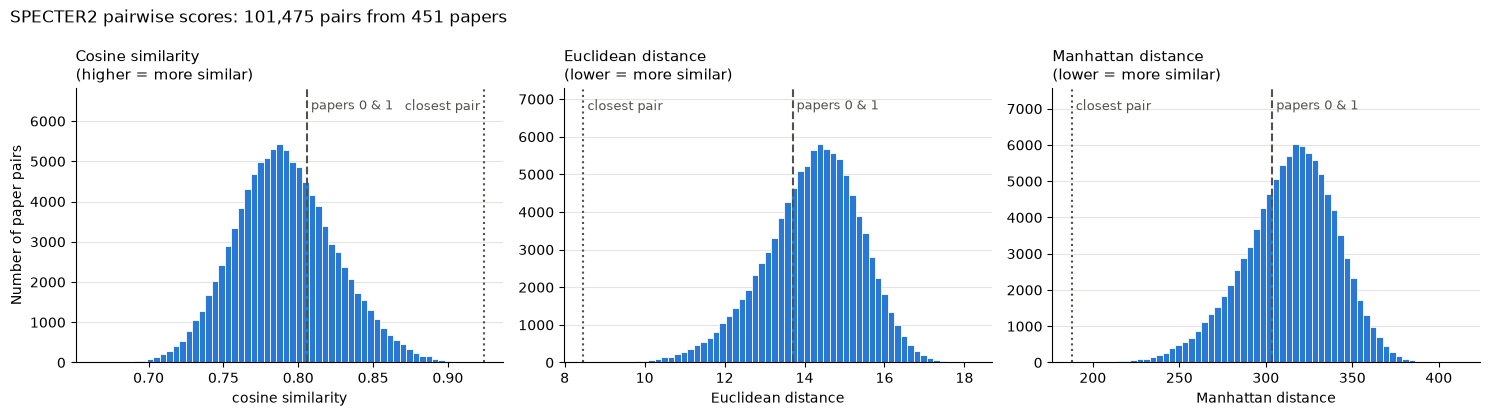

In [20]:
import matplotlib.pyplot as plt

rows, cols = np.triu_indices(len(specter_embeddings), k=1)  # each pair of different papers once

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, matrix) in zip(axes, specter_matrices.items()):
    higher_is_closer = name == "cosine similarity"
    pair_values = matrix[rows, cols]
    closest = pair_values.max() if higher_is_closer else pair_values.min()

    ax.hist(pair_values, bins=60, color="#2a78d6", edgecolor="white", linewidth=0.6)
    top = ax.get_ylim()[1]
    ax.set_ylim(top=top * 1.2)  # headroom so the labels sit above the bars
    for value, label, style in [(matrix[0, 1], "papers 0 & 1", "--"), (closest, "closest pair", ":")]:
        ax.axvline(value, color="#52514e", linestyle=style, linewidth=1.5)
        label_on_left = value == closest and higher_is_closer  # keep the edge label inside the plot
        ax.text(value, top * 1.12, f" {label} ", ha="right" if label_on_left else "left",
                va="center", color="#52514e", fontsize=9)

    direction = "higher = more similar" if higher_is_closer else "lower = more similar"
    ax.set_title(f"{name.capitalize()}\n({direction})", loc="left", fontsize=11)
    ax.set_xlabel(name)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)

    print(f"{name:20s} median {np.median(pair_values):8.3f} | middle 90% of pairs: "
          f"{np.percentile(pair_values, 5):.3f} to {np.percentile(pair_values, 95):.3f}")

axes[0].set_ylabel("Number of paper pairs")
fig.suptitle(f"SPECTER2 pairwise scores: {len(rows):,} pairs from {len(specter_embeddings)} papers", x=0.01, ha="left")
fig.tight_layout()
plt.show()

Cosine similarities all seem to be quite high, meaning that even completely unrelated papers will have a cosine similarity of 0.7+. Maybe this is because all research papers have a similar tone, but I thought this would be less of an issue for an embedding model trained on research papers only. 

### Sanity check: abstracts of the closest pair

In [21]:
import textwrap

# closest pair under cosine similarity (all three measures picked the same pair)
cosine = specter_matrices["cosine similarity"]
rows, cols = np.triu_indices_from(cosine, k=1)
best = cosine[rows, cols].argmax()

for index in (rows[best], cols[best]):
    paper = works_clean.iloc[index]
    print(f"[{index}] {paper['title']}")
    print(f"Source: {paper['source_name']} ({paper['publication_year']}) | {paper['openalex_id']}\n")
    print(textwrap.fill(paper["abstract"], width=110), "\n")

[186] Preface
Source: The Ecumenical Review (2014) | https://openalex.org/W2332010821

All Things New: Faith, Formation and the Future It was my great joy to serve as Dean of the Global Ecumenical
Theological Institute (GETI) in conjunction with the 10th Assembly of the World Council of Churches (WCC).I
left this exciting event with a fresh spirit of hope for the future of the ecumenical movement and am
delighted that the Ecumenical Review has agreed to do this special issue as a way to share some of the fresh
perspectives growing out of this event with the wider Christian family.Our hope and dream in GETI was not only
for an event in Korea (as significant as that was) but rather that this event will plant the seed for "the
future of ecumenism and the transformation of world Christianity in the 21st century" (as we subtitled the
GETI).Publications such as this special edition of The Ecumenical Review are only the beginning of a wider
dialogue and a deeper building of ecumenical communi

These have the greatest similarity in all three distance metrics, however semantically they seem unrelated. 186 appears to be a review unrelated to research, while 335 appears to be a film review. This again shows that context != concept, as we learned in class. 

Both of these are not the kind of observations I want in my sample, suggesting that I need better data cleaning first and foremost. The exact similarity metric I choose does not appear to matter as much, but I will check that below by comparing to what extent the 10 nearest neighbors are shared on average between distance metrics. This can be done with Jaccard similarity. 

### Do the measures agree on each paper's 10 nearest neighbors?

In [22]:
from itertools import combinations

k = 10

def nearest_neighbors(matrix, higher_is_closer, k):
    """Indices of each paper's k nearest neighbors, excluding the paper itself."""
    scores = -matrix if higher_is_closer else matrix.copy()  # make "smaller = closer" for every measure
    np.fill_diagonal(scores, np.inf)                         # a paper is not its own neighbor
    return np.argsort(scores, axis=1)[:, :k]

neighbors = {name: nearest_neighbors(matrix, name == "cosine similarity", k)
             for name, matrix in specter_matrices.items()}

for name_a, name_b in combinations(neighbors, 2):
    shared = np.array([len(set(a) & set(b)) for a, b in zip(neighbors[name_a], neighbors[name_b])])
    jaccard = shared / (2 * k - shared)  # |A ∩ B| / |A ∪ B| for two lists of k papers each
    print(f"{name_a} vs {name_b}:")
    print(f"  mean Jaccard {jaccard.mean():.3f} | on average {shared.mean():.1f} of {k} neighbors shared | "
          f"identical lists for {(shared == k).mean():.0%} of papers | lowest Jaccard {jaccard.min():.3f}")

cosine similarity vs Euclidean distance:
  mean Jaccard 0.942 | on average 9.7 of 10 neighbors shared | identical lists for 70% of papers | lowest Jaccard 0.667
cosine similarity vs Manhattan distance:
  mean Jaccard 0.833 | on average 9.0 of 10 neighbors shared | identical lists for 27% of papers | lowest Jaccard 0.429
Euclidean distance vs Manhattan distance:
  mean Jaccard 0.840 | on average 9.1 of 10 neighbors shared | identical lists for 29% of papers | lowest Jaccard 0.538


From the results it seems like they all agree strongly with Jaccard scores of above 0.8 in all comparisons, however Manhattan distance has significantly less identical lists of neighbors.

## Summary of my process, results, and next steps

I tested the methods on a development sample of 800 English-language OpenAlex articles from 2013–2016 (200 random papers per year, all fields), not yet on the field I will study. 296 papers (37%) had no abstract, which left 502 after my first filter of more than 20 characters.

**Choosing a representation.** In a separate exploratory notebook I compared count vectors, TF-IDF, and dense embeddings (MiniLM). Count vectors and TF-IDF found largely the same 10 nearest neighbors, while the embeddings found quite different ones. I chose dense embeddings because they seem to be the most popular in recent literature because they capture meaning beyond shared words.

**What didn't work, and how I revised it.**
1. *Token limit.* MiniLM cuts text off after 256 tokens (and was trained on only 128). About 40% of my abstracts were truncated, losing the end of the abstract, which usually holds the results and conclusions. I switched to SPECTER2, which is trained on scientific papers, accepts 512 tokens, and expects the title plus the abstract. With titles added, only 4.2% of inputs are truncated. The truncated share differed by year (1.7% in 2013 vs 6.1% in 2015), which matters for a year-by-year design: truncation could change the measurement over time.
2. *Software setup.* SPECTER2 needs the `adapters` library to load its "proximity" adapter, the version intended for finding similar papers. Getting it to work required pinning older package versions and reinstalling PyTorch, and a stale notebook kernel produced a confusing import error until I restarted it.
3. *Data quality.* Sorting and reading the abstracts showed that many were not real abstracts: placeholders ("International audience", "No abstract available."), author lists, and Japanese, Chinese, Russian text, even though the query requested English. I added a stricter filter (at least 30 words, mostly Latin script, a minimum share of common English words, no duplicates) and stripped "Abstract" labels and publisher copyright lines. This left 451 papers. The trade-off is that a few genuine but very short abstracts might have also been dropped.

**Testing the similarity measures.** SPECTER2's documentation points to the original SPECTER paper, which trained and evaluated the model using Euclidean distance. Cosine similarity ranks papers the same way only if vectors are normalized to length 1, which SPECTER2's are not. I computed cosine, Euclidean, and Manhattan matrices in one loop.
- *Distribution.* SPECTER2 cosine similarities are tightly bunched (the middle 90% of pairs fall between 0.74 and 0.85). An unrelated pair (a glaucoma device and teamwork communication) scored 0.81, compared with −0.09 for the same pair under MiniLM. SPECTER2's vectors seem to share a common direction, so only the ranking of scores is meaningful, not their absolute values.
- *Sanity check.* The closest pair under all three measures was a church-journal "Preface" and a record whose abstract is a review of a Hawking biopic filed under the title "Ancient galaxy found to be surprisingly dusty", an OpenAlex title–abstract mismatch. Neither is research. The model grouped them because both are informal, first-person prose, which shows that context ≠ concept.
- *Agreement between measures.* Jaccard similarity of each paper's 10 nearest neighbors was 0.94 for cosine vs Euclidean (9.7 of 10 neighbors shared on average) and about 0.83–0.84 for Manhattan vs either (about 9 of 10). Manhattan produced identical neighbor lists for far fewer papers (27–29% vs 70%).

**What I learned.** The choice of measure matters much less than what is in the data. For my project I will use Euclidean distance, since it matches how SPECTER2 was trained and the knowledge-extent measure I plan to use (the maximum distance from the centroid). Because that measure depends on the single most extreme paper in each sample, non-research items like the preface and the mislabeled film review could drive it if they sit far from the rest. Data cleaning can have a big impact on results. It is easy to miss things without actually looking into the data and doing sanity checks.

**Next steps.**
- Exclude non-research items: use OpenAlex's `is_paratext` filter, flag titles such as "Preface" or "Editorial".
- Decide whether to compute distances on raw or length-normalized vectors, although it probably will not matter much.
- Validate the embeddings the way Motohashi et al. did, by testing whether papers that cite each other are closer than random pairs.
- Select my field and embed larger samples. Later, use the field composition of each paper's nearest neighbors (following Motohashi et al.) to measure interdisciplinarity.

## Reflection on social implications

My project asks how the semantic breadth of a field changes as its publication volume grows. Week 1's experiments showed that a measure of "breadth" is only as meaningful as the decisions about what counts as a scientific paper.

First, the dataset itself is a social product, representing human research output over the years. OpenAlex labeled prefaces, news items, and a film review as "articles", and labeled Japanese, Russian, and Portuguese abstracts as English. More than a third of the sample had no abstract at all, often because of publisher policies on sharing abstracts. Filtering to clean English abstracts means I will be measuring the breadth of *English-language science with available abstracts*, not science as a whole. If the share of non-English publications or missing abstracts changes over time, part of any trend I find could reflect who is visible in the database rather than what researchers are studying. I should report these coverage changes alongside my results.

The closest-pair result illustrates the "context ≠ concept" idea from week 2 and lab 2. SPECTER2 placed a church-journal preface next to a film review because both are informal, first-person, reflective prose, not because they share a topic. Embeddings encode how something is written as well as what it is about. This matters for my research question: if scientific writing becomes more standardized over time (for example, through structured abstracts or templated writing under publishing pressure), semantic breadth could appear to shrink because styles converge, even if ideas do not.

SPECTER was trained to place papers close together when one cites the other, so its "semantic" distances partly reflect citation practices: who reads and cites whom. Chu and Evans (2021) found that attention concentrates on established work as fields grow. A citation-trained embedding may carry some of that concentration into its geometry, so semantic breadth and citation structure are not fully independent processes.

This connects to our class discussion about ground truth: OpenAlex topics are classifier outputs with 82% accuracy and embedding distances reflect training data. A better way to get ground truth labels might be through known journals in specific fields. Kozlowski and Evans's work shows that embeddings can track cultural change (social class construct) over time, using a fixed measuring instrument. That is why I will use one model and one cleaning procedure for every year. This week moved me closer to answering my research question by showing that the main threat to validity is not the choice of distance measure but the definition of the corpus, which I can now address before computing breadth.